In [179]:
import pandas as pd
import numpy as np

dftrain = pd.read_csv("train.csv")

dftrain.head()

,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,gcs_total,pain_score,weight_kg,height_cm,bmi,shock_index,news2_score,disposition,ed_los_hours,triage_acuity
0,TG-UXRGA9UCO,SITE-TMP-01,NURSE-0033,walk-in,6,Monday,5,spring,morning,43,...,14,7,52.3,165.4,19.1,0.725,8,discharged,7.35,2
1,TG-B19DBBS2G,SITE-HEL-01,NURSE-0001,walk-in,6,Thursday,4,spring,morning,72,...,15,-1,73.3,164.4,27.1,0.739,1,discharged,0.70,5
2,TG-GZ97W7M6V,SITE-HEL-02,NURSE-0005,walk-in,8,Saturday,4,spring,morning,82,...,15,3,77.1,183.7,22.8,0.798,2,discharged,0.63,5
3,TG-THIB2TN9Q,SITE-HEL-02,NURSE-0026,police,7,Sunday,3,spring,morning,50,...,15,7,49.6,172.6,16.6,0.812,2,discharged,1.99,3
4,TG-J3U3LQ2QY,SITE-HEL-02,NURSE-0044,walk-in,5,Tuesday,5,spring,night,62,...,15,4,71.9,173.4,23.9,0.812,2,transferred,3.58,3


In [180]:
df_train_clean = dftrain.dropna()
print(len(df_train_clean), len(dftrain))

72669 80000


In [181]:
# Do Feature Engineering

from typing import List

print(df_train_clean.columns.to_list())

def systolic_blood_pressure(s):
    if 90 <= s <= 120:
        return 0
    if s < 90:
        return (s - 90) ** 2
    if 140 >= s > 120:
        return abs(s - 120) ** 1.5
    else:
        return 89.44 + ((s - 140) ** 2)

def diastolic_blood_pressure(s):
    if 60 <= s <= 80:
        return 0
    if s < 60:
        return (s - 60) ** 2
    if 90 >= s > 80:
        return abs(s - 80) ** 1.5
    else:
        return 31.62 + ((s - 90) ** 2)

def map(s):
    if 70 <= s <= 100:
        return 0
    if s < 70:
        return (s - 70) ** 2
    if 100 <= s < 110:
        return abs(s - 100)
    else:
        return abs(s - 110) ** 2

def pulse_pressure(p):
    return (p - 40) ** 4

def respiratory_rate(age: List[float], respiratory_rate: List[float]) -> List[float]:
    res = [0.0] * len(age)
    for i in range(len(age)):
        if age[i] < 1:
            res[i] = abs(respiratory_rate[i] - 45) ** 4
            continue
        elif age[i] < 2:
            res[i] = abs(respiratory_rate[i] - 30) ** 4
            continue
        elif 3 < age[i] < 6:
            res[i] = abs(respiratory_rate[i] - 25) ** 4
            continue
        elif 6 < age[i] < 12:
            res[i] = abs(respiratory_rate[i] - 22.5) ** 4
            continue
        else:
            res[i] = abs(respiratory_rate[i] - 16) ** 4
            continue
    return res

def temp(t):
    if 36 < t < 38:
        return 0
    if t > 38:
        return (t - 38) ** 4
    return abs(36 - t) ** 4

def bmi(b):
    if 18.5 <= b <= 25:
        return 0
    if b < 18.5:
        return (b - 18.5) ** 4
    else:
        return (25 - b) ** 4

x_train = pd.DataFrame()
x_train['arrival_mode'] = df_train_clean['arrival_mode'].apply(lambda x: 1 if x in ["ambulance", 'transfer', 'police', 'helicoper'] else 0)
x_train['age_group'] = df_train_clean['age_group'].apply(lambda x: 2 if x in ['elderly', 'pediatric'] else 1)
x_train['age'] = df_train_clean['age'].astype(int).apply(lambda x: abs(x - 35) ** 2)
x_train['num_prior_ed_visits_12m'] = df_train_clean['num_prior_ed_visits_12m'].astype(int)
x_train['num_prior_admissions_12m'] = df_train_clean['num_prior_admissions_12m'].astype(int).apply(lambda x: x ** 1.2)
x_train['num_active_medications'] = df_train_clean['num_active_medications'].astype(int).apply(lambda x: x ** 1.5)
x_train['num_comorbidities'] = df_train_clean['num_comorbidities'].astype(int).apply(lambda x: x ** 1.8)
x_train['systolic_bp'] = df_train_clean['systolic_bp'].astype(float).apply(systolic_blood_pressure)
x_train['diastolic_bp'] = df_train_clean['diastolic_bp'].astype(float).apply(diastolic_blood_pressure)
x_train['mean_arterial_pressure'] = df_train_clean['mean_arterial_pressure'].astype(float).apply(map)
x_train['pulse_pressure'] = df_train_clean['pulse_pressure'].astype(float).apply(pulse_pressure)
x_train['heart_rate'] = df_train_clean['heart_rate'].astype(float).apply(lambda x: abs(x - 72) ** 4)
x_train['respiratory_rate'] = pd.array(respiratory_rate(df_train_clean['age'].astype(float).tolist(), df_train_clean['respiratory_rate'].astype(float).tolist()))
x_train['temperature_c'] = df_train_clean['temperature_c'].astype(float).apply(temp)
x_train['spo2'] = df_train_clean['spo2'].astype(float).apply(lambda x: (100 - x) ** 4)
x_train['gcs_total'] = df_train_clean['gcs_total'].astype(int).apply(lambda x: (15 - x) ** 4)
x_train['pain_score'] = df_train_clean['pain_score'].astype(int)
x_train['bmi'] = df_train_clean['bmi'].astype(float).apply(bmi)
x_train['shock_index'] = df_train_clean['shock_index'].astype(float)
x_train['news2_score'] = df_train_clean['news2_score'].astype(int)

y_train = pd.DataFrame()
y_train['triage_acuity'] = df_train_clean['triage_acuity'].astype(int).apply(lambda x: 5 - x)

print(len(x_train))
x_train.head()

['patient_id', 'site_id', 'triage_nurse_id', 'arrival_mode', 'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season', 'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'disposition', 'ed_los_hours', 'triage_acuity']
72669


,arrival_mode,age_group,age,num_prior_ed_visits_12m,num_prior_admissions_12m,num_active_medications,num_comorbidities,systolic_bp,diastolic_bp,mean_arterial_pressure,pulse_pressure,heart_rate,respiratory_rate,temperature_c,spo2,gcs_total,pain_score,bmi,shock_index,news2_score
0,0,1,64,0,0.0,8.000000,42.224253,121.000000,6.250000,28.09,1.171351e+05,4.669489e+04,13.0321,0.0000,3895.0081,1,7,0.0000,0.725,8
1,0,2,1369,0,0.0,31.622777,42.224253,40.020157,43.180000,6.20,8.352100e+00,4.097152e+05,2.0736,0.0000,0.1296,0,-1,19.4481,0.739,1
2,0,2,2209,0,0.0,46.872167,115.619334,0.000000,5.994748,0.00,6.690586e+05,1.679616e+02,2.8561,0.0000,0.0000,0,3,0.0000,0.798,2
3,1,1,225,3,1.0,8.000000,7.224674,53.509700,67.240000,0.00,3.231941e+06,1.874161e+06,6.5536,0.0016,256.0000,0,7,13.0321,0.812,2
4,0,1,729,2,0.0,31.622777,163.986486,89.450000,0.000000,0.00,3.722098e+05,3.023738e+06,6.5536,0.0000,0.6561,0,4,0.0000,0.812,2


In [182]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, Y_train, Y_test = train_test_split(
    x_train, y_train, test_size=0.10, random_state=42
)

model = LinearRegression()
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# X_train_scaled = X_train
# X_test_scaled = X_test

model.fit(X_train_scaled, Y_train)

print(X_test_scaled[:5])

Y_pred = np.round(model.predict(X_test_scaled))

print(f"Weights: {model.coef_[0]}\n")
print(f"Intercept: {model.intercept_[0]:.4f}\n")
print(f"Mean Squared Error (MSE): {mean_squared_error(Y_test, Y_pred):.4f}\n")
print(f"R² Score (Coefficient of Determination): {r2_score(Y_test, Y_pred):.4f}\n")

print(Y_pred[:5], "\n")
print(Y_test.head(5))



[[ 1.18005198  1.35332944  1.67652918  0.37670868  1.9081291   2.69264275
   2.44797547  1.36597439 -0.25057995 -0.06871719  0.10296826 -0.20908456
  -0.19503665 -0.23341681 -0.13108493 -0.18915924 -0.50465385 -0.11571296
  -0.61060988 -0.39641148]
 [-0.8474203  -0.73891838 -0.68130598  2.44043905  0.54286424 -0.12953532
  -0.31051661 -0.12229331 -0.3376241  -0.21720115 -0.18431393 -0.12199931
  -0.19030751  0.03007882 -0.07379082 -0.18915924  1.27384444 -0.11616547
  -0.18966893  0.75311116]
 [-0.8474203   1.35332944  0.6558922  -0.31120144 -0.50944678 -0.53942049
   1.47500051 -0.34213041 -0.3376241  -0.21720115 -0.27613194 -0.27566024
  -0.20180845 -0.23341681 -0.17185379 -0.18915924 -0.80107024 -0.11616547
  -0.47433403 -0.85622054]
 [ 1.18005198  1.35332944 -0.04272563  0.37670868 -0.50944678 -0.70159714
  -0.99014531 -0.07801031  0.32419262 -0.163057   -0.28029481 -0.27154694
  -0.1981564  -0.23341681 -0.17806232 -0.18915924  0.68101168 -0.11616547
  -1.27381901 -0.62631601]
 [-0

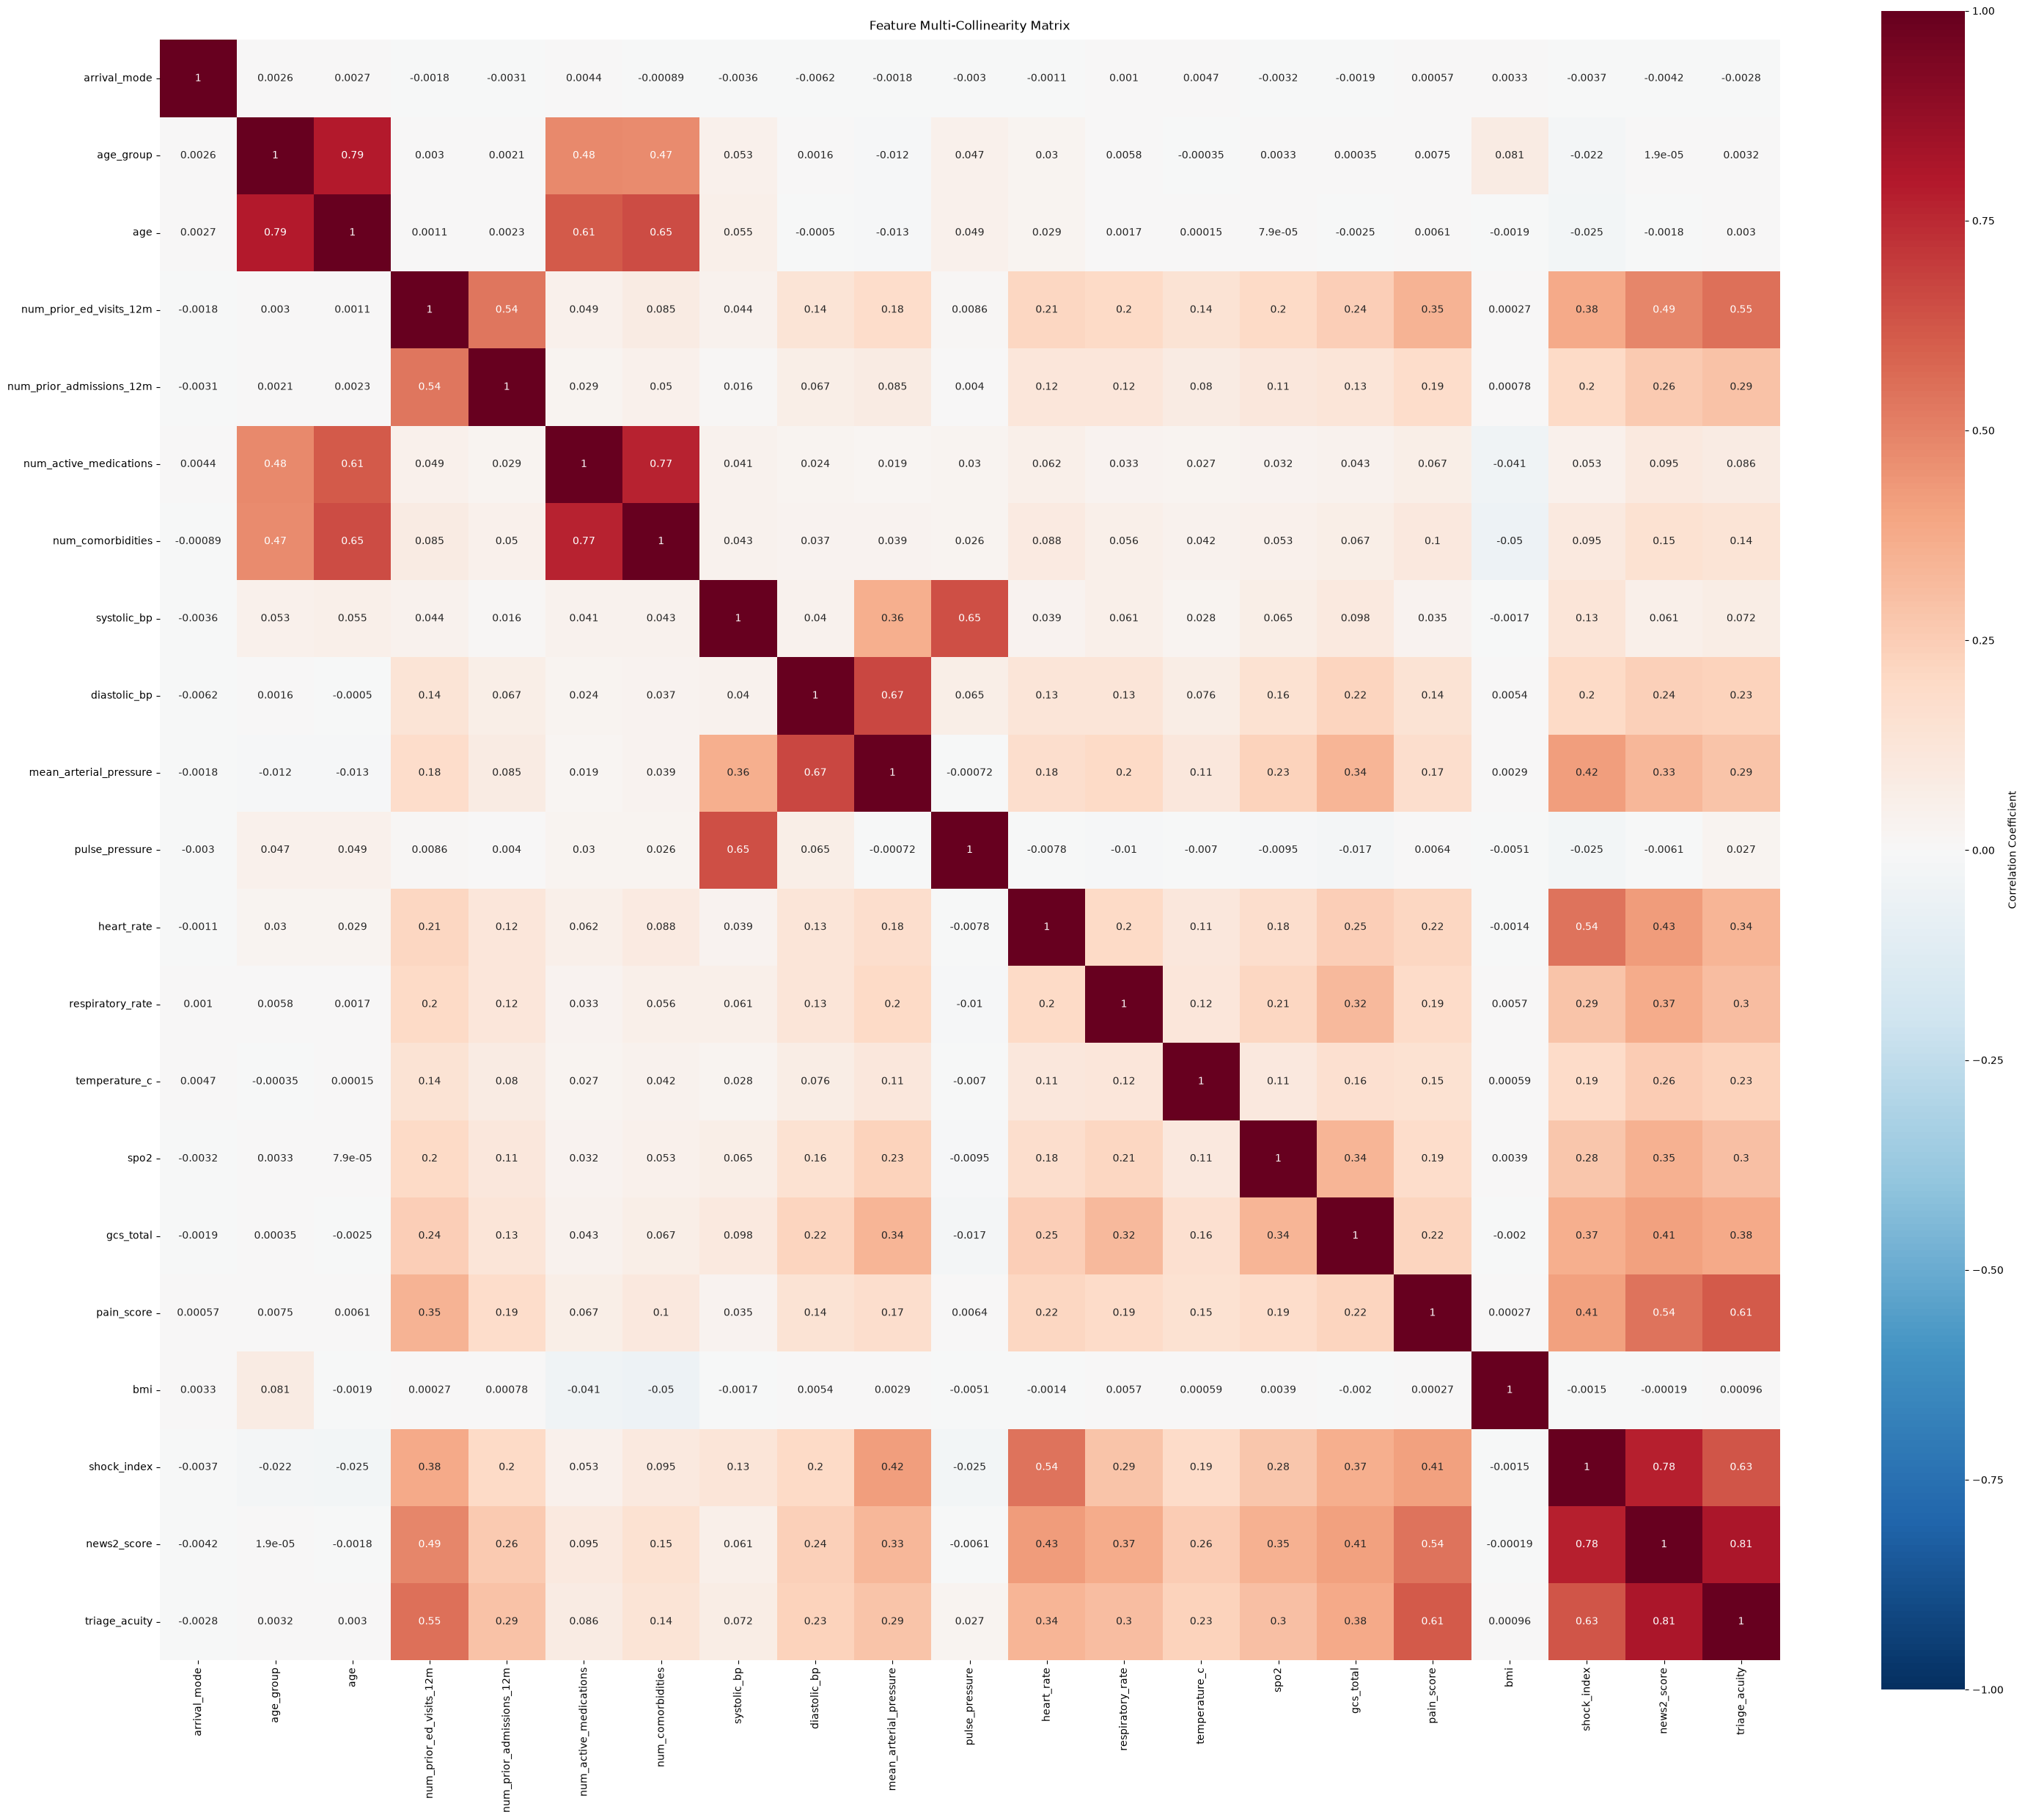

In [183]:
import seaborn as sns
import matplotlib.pyplot as plt
import copy

plt.figure(figsize=(30, 25))
# Generate the correlation matrix of your independent variables
features = copy.deepcopy(x_train)
features['triage_acuity'] = y_train
feature_corr = features.corr()

sns.heatmap(
    feature_corr,
    annot=True,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Correlation Coefficient"},
)
plt.title("Feature Multi-Collinearity Matrix", fontsize=12, pad=10)
plt.tight_layout()
plt.show()


In [184]:
modelFile = open("model.csv", "w")
modelFile.write(",".join([str(k) for k in model.coef_.tolist()[0]]))
modelFile.write("\n")
modelFile.write(str(model.intercept_[0]))

print()

## <div align='center'>The Model is now complete</div>

### Achievements:
- Mean Squared Error (MSE): 0.0000
- R² Score (Coefficient of Determination): 1.0000

This means that no triage_acuity score was wrong and priority was assigned correctly in every case

In [185]:
# Now read the actual test file and predict outputs in a file named predictions
dftest = pd.read_csv("test.csv")

# Clean the dataset, by dropping N/A values

testing_clean = dftest.fillna(0)
print(len(testing_clean), len(dftest))

# Do Feature Engineering

print(testing_clean.columns.to_list())

def systolic_blood_pressure(s):
    if 90 <= s <= 120:
        return 0
    if s < 90:
        return (s - 90) ** 2
    if 140 >= s > 120:
        return abs(s - 120) ** 1.5
    else:
        return 89.44 + ((s - 140) ** 2)

def diastolic_blood_pressure(s):
    if 60 <= s <= 80:
        return 0
    if s < 60:
        return (s - 60) ** 2
    if 90 >= s > 80:
        return abs(s - 80) ** 1.5
    else:
        return 31.62 + ((s - 90) ** 2)

def map(s):
    if 70 <= s <= 100:
        return 0
    if s < 70:
        return (s - 70) ** 2
    if 100 <= s < 110:
        return abs(s - 100)
    else:
        return abs(s - 110) ** 2

def pulse_pressure(p):
    return (p - 40) ** 4

def respiratory_rate(age: List[float], respiratory_rate: List[float]) -> List[float]:
    res = [0.0] * len(age)
    for i in range(len(age)):
        if age[i] < 1:
            res[i] = abs(respiratory_rate[i] - 45) ** 4
            continue
        elif age[i] < 2:
            res[i] = abs(respiratory_rate[i] - 30) ** 4
            continue
        elif 3 < age[i] < 6:
            res[i] = abs(respiratory_rate[i] - 25) ** 4
            continue
        elif 6 < age[i] < 12:
            res[i] = abs(respiratory_rate[i] - 22.5) ** 4
            continue
        else:
            res[i] = abs(respiratory_rate[i] - 16) ** 4
            continue
    return res

def temp(t):
    if 36 < t < 38:
        return 0
    if t > 38:
        return (t - 38) ** 4
    return abs(36 - t) ** 4

def bmi(b):
    if 18.5 <= b <= 25:
        return 0
    if b < 18.5:
        return (b - 18.5) ** 4
    else:
        return (25 - b) ** 4

testing = pd.DataFrame()
testing['arrival_mode'] = testing_clean['arrival_mode'].apply(lambda x: 1 if x in ["ambulance", 'transfer', 'police', 'helicoper'] else 0)
testing['age_group'] = testing_clean['age_group'].apply(lambda x: 2 if x in ['elderly', 'pediatric'] else 1)
testing['age'] = testing_clean['age'].astype(int).apply(lambda x: abs(x - 35) ** 2)
testing['num_prior_ed_visits_12m'] = testing_clean['num_prior_ed_visits_12m'].astype(int)
testing['num_prior_admissions_12m'] = testing_clean['num_prior_admissions_12m'].astype(int).apply(lambda x: x ** 1.2)
testing['num_active_medications'] = testing_clean['num_active_medications'].astype(int).apply(lambda x: x ** 1.5)
testing['num_comorbidities'] = testing_clean['num_comorbidities'].astype(int).apply(lambda x: x ** 1.8)
testing['systolic_bp'] = testing_clean['systolic_bp'].astype(float).apply(systolic_blood_pressure)
testing['diastolic_bp'] = testing_clean['diastolic_bp'].astype(float).apply(diastolic_blood_pressure)
testing['mean_arterial_pressure'] = testing_clean['mean_arterial_pressure'].astype(float).apply(map)
testing['pulse_pressure'] = testing_clean['pulse_pressure'].astype(float).apply(pulse_pressure)
testing['heart_rate'] = testing_clean['heart_rate'].astype(float).apply(lambda x: abs(x - 72) ** 4)
testing['respiratory_rate'] = pd.array(respiratory_rate(testing_clean['age'].astype(float).tolist(), testing_clean['respiratory_rate'].astype(float).tolist()))
testing['temperature_c'] = testing_clean['temperature_c'].astype(float).apply(temp)
testing['spo2'] = testing_clean['spo2'].astype(float).apply(lambda x: (100 - x) ** 4)
testing['gcs_total'] = testing_clean['gcs_total'].astype(int).apply(lambda x: (15 - x) ** 4)
testing['pain_score'] = testing_clean['pain_score'].astype(int)
testing['bmi'] = testing_clean['bmi'].astype(float).apply(bmi)
testing['shock_index'] = testing_clean['shock_index'].astype(float)
testing['news2_score'] = testing_clean['news2_score'].astype(int)

print(len(testing))

newScaler = StandardScaler()

testPredictions = model.predict(newScaler.fit_transform(testing)).reshape(-1)
ids = testing_clean['patient_id']

testingPreds = pd.DataFrame()
testingPreds['patient_id'] = testing_clean['patient_id']
testingPreds['triage_acuity'] = 5 - np.round(testPredictions)
testingPreds['triage_acuity'] = testingPreds['triage_acuity'].astype("Int64")

testingPreds.to_csv('results.csv', index=False)

testingPreds.head(15)

20000 20000
['patient_id', 'site_id', 'triage_nurse_id', 'arrival_mode', 'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season', 'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score']
20000


,patient_id,triage_acuity
0,TG-FZUFCRZS3,1
1,TG-SSCOXTYI1,3
2,TG-JY74ZR35D,2
3,TG-JDKD5G62X,4
4,TG-J1BSAAXR0,4
5,TG-5YERUAA5X,4
6,TG-IVU18ZJCF,2
7,TG-K5XYMWTCG,2
8,TG-RCAR2TLEI,4
9,TG-YNDUR0KGO,4


In [186]:
x_train.head()

,arrival_mode,age_group,age,num_prior_ed_visits_12m,num_prior_admissions_12m,num_active_medications,num_comorbidities,systolic_bp,diastolic_bp,mean_arterial_pressure,pulse_pressure,heart_rate,respiratory_rate,temperature_c,spo2,gcs_total,pain_score,bmi,shock_index,news2_score
0,0,1,64,0,0.0,8.000000,42.224253,121.000000,6.250000,28.09,1.171351e+05,4.669489e+04,13.0321,0.0000,3895.0081,1,7,0.0000,0.725,8
1,0,2,1369,0,0.0,31.622777,42.224253,40.020157,43.180000,6.20,8.352100e+00,4.097152e+05,2.0736,0.0000,0.1296,0,-1,19.4481,0.739,1
2,0,2,2209,0,0.0,46.872167,115.619334,0.000000,5.994748,0.00,6.690586e+05,1.679616e+02,2.8561,0.0000,0.0000,0,3,0.0000,0.798,2
3,1,1,225,3,1.0,8.000000,7.224674,53.509700,67.240000,0.00,3.231941e+06,1.874161e+06,6.5536,0.0016,256.0000,0,7,13.0321,0.812,2
4,0,1,729,2,0.0,31.622777,163.986486,89.450000,0.000000,0.00,3.722098e+05,3.023738e+06,6.5536,0.0000,0.6561,0,4,0.0000,0.812,2


In [187]:
testing.head()

,arrival_mode,age_group,age,num_prior_ed_visits_12m,num_prior_admissions_12m,num_active_medications,num_comorbidities,systolic_bp,diastolic_bp,mean_arterial_pressure,pulse_pressure,heart_rate,respiratory_rate,temperature_c,spo2,gcs_total,pain_score,bmi,shock_index,news2_score
0,0,1,121,2,2.297397,8.000000,12.125733,289.000000,0.0,0.0,4.064296e+06,118.5921,13107.9601,0.0625,15735.1936,625,10,53.1441,1.032,13
1,1,1,324,0,0.000000,8.000000,25.157776,0.000000,0.0,0.0,1.944810e+01,183603.6801,447.7456,0.6561,0.0000,0,9,39.0625,0.827,4
2,1,2,2809,4,0.000000,14.696938,25.157776,37.482369,0.0,0.0,1.731891e+05,133086.3361,18738.8721,0.4096,789.0481,1,6,7163.9296,0.694,9
3,0,1,576,2,1.000000,27.000000,63.095734,69.475240,0.0,0.0,1.222831e+05,1575.2961,1.4641,0.0000,1.0000,0,4,10000.0000,0.572,0
4,0,1,81,0,0.000000,2.828427,12.125733,8100.000000,3600.0,4900.0,2.560000e+06,1785.0625,0.4096,0.0000,0.0000,0,1,16.0000,0.000,0
